In [1]:
import obspy
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.cm as cm
from F_statistic import compute_F_statistic

In [2]:
file_dir = "/home/jqxie/data/Data/hydrophone_data/CTBTO_H08S_20030514/"
file_name = "H08S?_2003_134-.SAC"

In [3]:
st = obspy.read(file_dir + file_name)
t3 = st[0].stats.sac.t3
tr0 = st[0]

In [4]:
time_start,time_one_slice,time_slide,time_length = t3+1000,5,5,5000
time_windows,azimuths,F_statistic = compute_F_statistic(st,time_start,time_one_slice,time_slide,time_length)

/tmp/ipykernel_731468/891422757.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('jet')


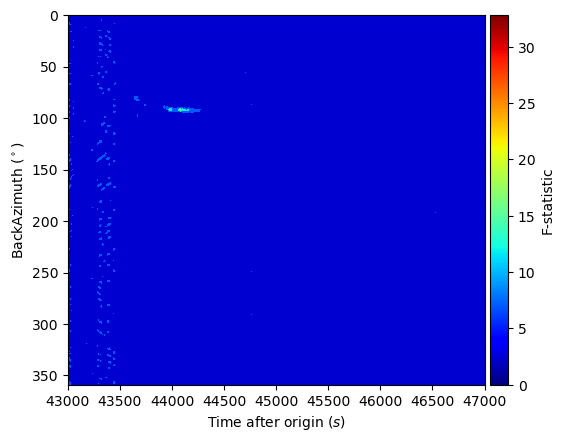

In [5]:
fig,axs=plt.subplots(1)

vmin = 0.0

cmap = cm.get_cmap('jet')
norm = plt.Normalize(vmin=vmin, vmax=np.max(F_statistic))  # 创建规格化对象，使颜色条的范围与我们的数据相对应
color = cmap(norm(F_statistic))  # 使用 colormap 来获取每一层的颜色

contour_plot = axs.contourf(time_windows,azimuths,F_statistic, vmin=vmin, cmap=cmap)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)

plt.colorbar(sm, ax=axs, label='F-statistic', pad=0.01)

axs.set(xlabel='Time after origin $(s)$',ylabel='BackAzimuth $(^\circ)$')
axs.set_xlim([43000, 47000])
axs.invert_yaxis()

In [28]:
time_start,time_one_slice,time_slide,time_length = t3+3000,10,10,9000
time_windows,azimuths,F_statistic = compute_F_statistic(st,time_start,time_one_slice,time_slide,time_length)

/tmp/ipykernel_23299/2384406280.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('jet')


[Text(0.5, 0, 'Time $(s)$'), Text(0, 0.5, 'BackAzimuth $(^\\circ)$')]

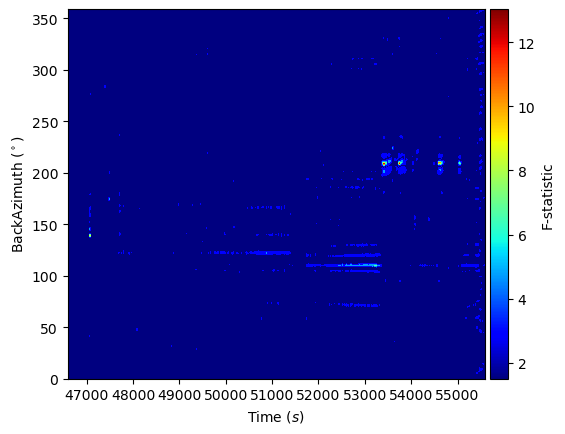

In [71]:
fig,axs=plt.subplots(1)

vmin = 1.5

cmap = cm.get_cmap('jet')
norm = plt.Normalize(vmin=vmin, vmax=np.max(F_statistic))  # 创建规格化对象，使颜色条的范围与我们的数据相对应
color = cmap(norm(F_statistic))  # 使用 colormap 来获取每一层的颜色

contour_plot = axs.contourf(time_windows,azimuths,F_statistic, vmin=vmin, cmap=cmap)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)

plt.colorbar(sm, ax=axs, label='F-statistic', pad=0.01)

axs.set(xlabel='Time $(s)$', ylabel='BackAzimuth $(^\circ)$')
# axs.set_xlim([43000, 47600])

[Text(0.5, 0, 'Time (s)'), Text(0, 0.5, 'Azimuth (deg)')]

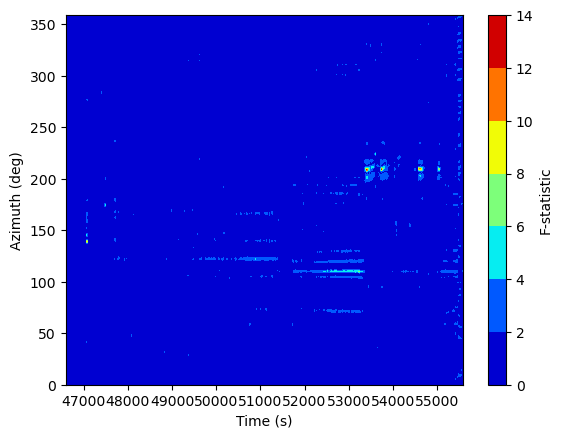

In [45]:
fig,axs=plt.subplots(1)

contour_plot = axs.contourf(time_windows,azimuths,F_statistic, cmap='jet')

plt.colorbar(contour_plot, label='F-statistic', ax=axs)
# plt.colorbar(axs.imshow(F_statistic,aspect='auto'))

axs.set(xlabel='Time (s)',ylabel='Azimuth (deg)')
# axs.set_xlim([43000, 47600])

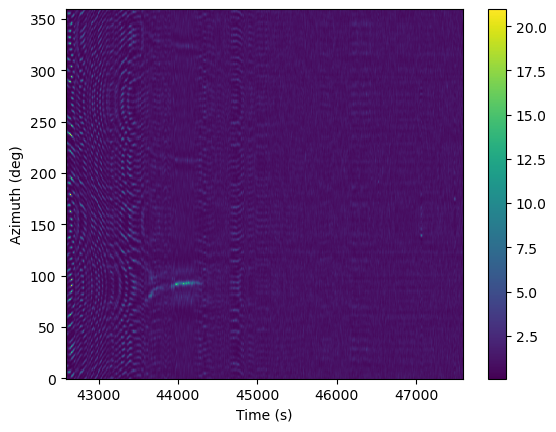

In [6]:
fig,axs=plt.subplots(1)
plt.colorbar(axs.pcolormesh(time_windows,azimuths,F_statistic,shading='auto'))
axs.set(xlabel='Time (s)',ylabel='Azimuth (deg)')
# plt.colorbar(axs.pcolormesh(time_windows,azimuths,F_statistic,shading='auto'))
# plt.colorbar(axs.imshow(F_statistic,aspect='auto'))

# axs.set(xlabel='Time (s)',ylabel='Azimuth (deg)')
plt.show()

In [7]:
# # Execute array_processing
# kwargs = dict(
#     # slowness grid: X min, X max, Y min, Y max, Slow Step
#     sll_x=-3.0, slm_x=3.0, sll_y=-3.0, slm_y=3.0, sl_s=0.03,
#     # sliding window properties
#     win_len=1.0, win_frac=0.05,
#     # frequency properties
#     frqlow=1.0, frqhigh=8.0, prewhiten=0,
#     # restrict output
#     semb_thres=-1e9, vel_thres=-1e9,
#     stime=tr0.stats.starttime + t3,
#     etime=tr0.stats.starttime + t3 + 1000,
# )
# # out = array_processing(st, **kwargs)

In [8]:
# slm_x = kwargs['slm_x']
# sll_x = kwargs['sll_x']
# slm_y = kwargs['slm_y']
# sll_y = kwargs['sll_y']
# sl_s = kwargs['sl_s']

In [9]:
# # check that sampling rates do not vary
# fs = stream[0].stats.sampling_rate
# if len(stream) != len(stream.select(sampling_rate=fs)):
#     msg = 'in sonic sampling rates of traces in stream are not equal'
#     raise ValueError(msg)

# grdpts_x = int(((slm_x - sll_x) / sl_s + 0.5) + 1)
# grdpts_y = int(((slm_y - sll_y) / sl_s + 0.5) + 1)

In [10]:
# delays = compute_delay(st, 45.0)

In [11]:
# geometry = get_geometry(stream, coordsys=coordsys, verbose=verbose)

In [12]:
# time_shift_table = get_timeshift(geometry, sll_x, sll_y,
#                                     sl_s, grdpts_x, grdpts_y)